In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')
sns.set_palette("colorblind")
pd.set_option('display.max_columns', 50)

In [7]:
df = pd.read_csv('/home/luka/Bureau/cours/4A/projet_fraude/data/processed/sampled_transactions.csv')

print("Avant optimisation :")
df.info(memory_usage='deep')

Avant optimisation :
<class 'pandas.DataFrame'>
RangeIndex: 4692821 entries, 0 to 4692820
Data columns (total 15 columns):
 #   Column          Dtype  
---  ------          -----  
 0   User            int64  
 1   Card            int64  
 2   Year            int64  
 3   Month           int64  
 4   Day             int64  
 5   Time            str    
 6   Amount          str    
 7   Use Chip        str    
 8   Merchant Name   int64  
 9   Merchant City   str    
 10  Merchant State  str    
 11  Zip             float64
 12  MCC             int64  
 13  Errors?         str    
 14  Is Fraud?       str    
dtypes: float64(1), int64(7), str(7)
memory usage: 1.9 GB


In [8]:
df['Amount'] = df['Amount'].str.replace('$', '', regex=False).astype('float32')

df['Year'] = df['Year'].astype('int16')
df['Month'] = df['Month'].astype('int8')
df['Day'] = df['Day'].astype('int8')
df['Card'] = df['Card'].astype('int8')

df['Zip'] = df['Zip'].astype('float32')

categorical_cols = ['Use Chip', 'Merchant City', 'Merchant State', 'Errors?', 'Is Fraud?']

for col in categorical_cols:
    df[col] = df[col].astype('category')


print("Après optimisation :")
df.info(memory_usage='deep')

Après optimisation :
<class 'pandas.DataFrame'>
RangeIndex: 4692821 entries, 0 to 4692820
Data columns (total 15 columns):
 #   Column          Dtype   
---  ------          -----   
 0   User            int64   
 1   Card            int8    
 2   Year            int16   
 3   Month           int8    
 4   Day             int8    
 5   Time            str     
 6   Amount          float32 
 7   Use Chip        category
 8   Merchant Name   int64   
 9   Merchant City   category
 10  Merchant State  category
 11  Zip             float32 
 12  MCC             int64   
 13  Errors?         category
 14  Is Fraud?       category
dtypes: category(5), float32(2), int16(1), int64(3), int8(3), str(1)
memory usage: 439.1 MB


## 1 - Quelle est la proportion exacte de fraude dans l'échantillon ? ##

Is Fraud?
No     99.868949
Yes     0.131051
Name: proportion, dtype: float64


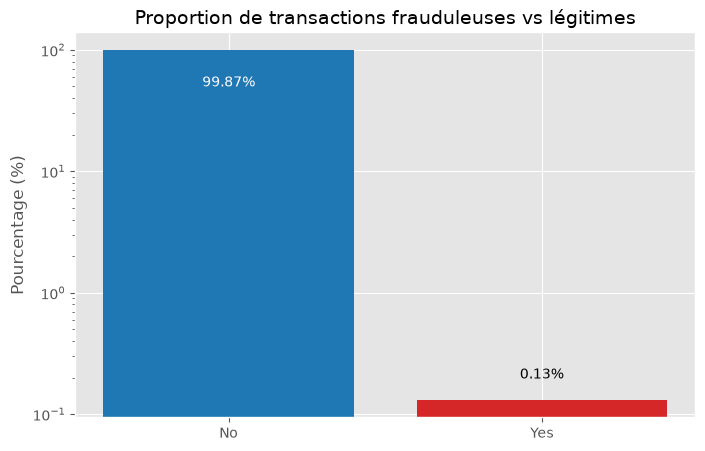

In [21]:
proportion = df['Is Fraud?'].value_counts(normalize=True)*100
print(proportion)

plt.figure(figsize=(8, 5))
plt.bar(proportion.index, proportion.values, color=['#1f77b4', '#d62728'])

plt.title("Proportion de transactions frauduleuses vs légitimes", fontsize=14)
plt.ylabel("Pourcentage (%)", fontsize=12)
plt.yscale('log')

plt.text(0, proportion.iloc[0]/2, f"{proportion.iloc[0]:.2f}%", ha='center', color='white')
plt.text(1, proportion.iloc[1]*1.5, f"{proportion.iloc[1]:.2f}%", ha='center')

plt.show()

Le taux de fraude observé dans notre échantillon s'élève à 0,13 %. Ce résultat est statistiquement fidèle à la réalité du dataset complet d'IBM, dont le taux de fraude global est d'environ 0,122 % (soit un peu moins de 30 000 fraudes pour 24 millions de transactions). Cette proximité confirme que notre méthode d'échantillonnage a préservé la distribution naturelle des données.

## 2 - Y a-t-il une différence de distribution des montants entre les transactions légitimes et frauduleuses ? ##

Statistiques des montants par type de transaction :


,count,mean,std,min,25%,50%,75%,max
Is Fraud?,,,,,,,,
No,4686671.0,42.453907,77.064049,-500.0,9.180000,28.740000,63.000000,5155.359863
Yes,6150.0,107.812416,195.847153,-500.0,18.192501,69.470001,153.205006,2890.229980


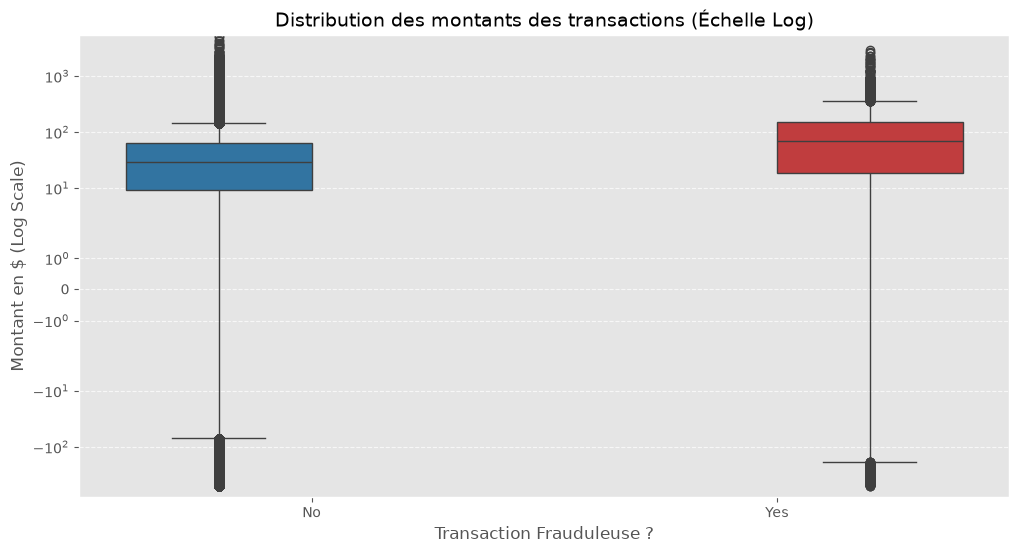

In [29]:
print("Statistiques des montants par type de transaction :")
display(df.groupby('Is Fraud?')['Amount'].describe())

plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x='Is Fraud?', y='Amount', hue='Is Fraud?',legend=False,palette=['#1f77b4', '#d62728'])
plt.yscale('symlog')

plt.title('Distribution des montants des transactions (Échelle Log)', fontsize=14)
plt.ylabel('Montant en $ (Log Scale)', fontsize=12)
plt.xlabel('Transaction Frauduleuse ?', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

L'analyse de la variable Amount révèle une différence de comportement entre les opérations légitimes et frauduleuses. La médiane d'une transaction frauduleuse est à 69,47 dollars, contre seulement 28,74 dollars pour une transaction normale, confirmant que les fraudeurs tendent à maximiser le montant volé par opération avant le blocage de la carte. Les moyennes confirment cette asymétrie (107,81 pour les fraudes contre 42,45 en temps normal). Toutefois, la forte superposition des quartiles supérieurs et la présence de nombreuses valeurs extrêmes (dépassant les 1 000 dollars) dans les deux classes démontrent que le montant seul est insuffisant pour discriminer parfaitement une fraude. Enfin, on observe des valeurs négatives (minimum observé à -500 $) correspondant probablement à des remboursements, il faudra probablement exclure ces valeurs par la suite.

## 3 - La fraude est-elle plus fréquente à certaines heures de la journée ? ##

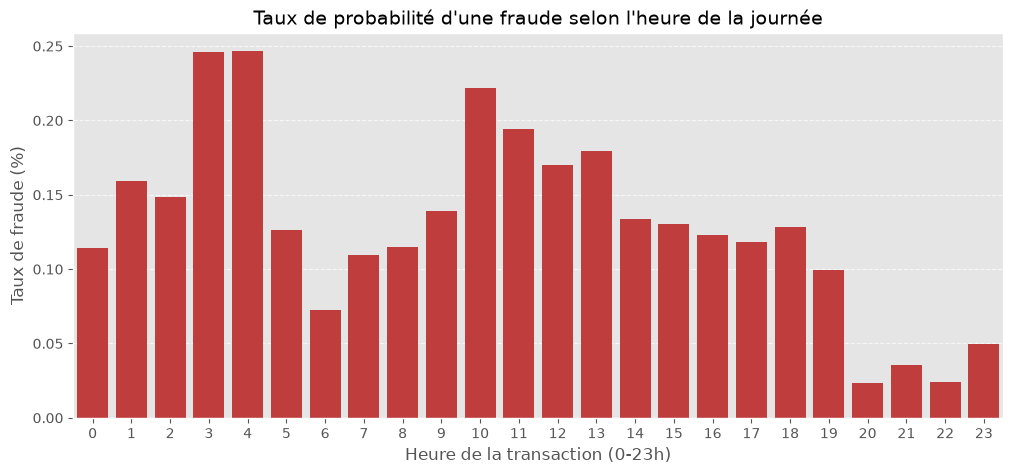

In [30]:
df['Hour'] = df['Time'].str.split(':').str[0].astype('int8')
df['Is_Fraud_Bin'] = df['Is Fraud?'].map({'No': 0, 'Yes': 1}).astype('int8')
hourly_fraud_rate = df.groupby('Hour')['Is_Fraud_Bin'].mean() * 100

plt.figure(figsize=(12, 5))


sns.barplot(x=hourly_fraud_rate.index, y=hourly_fraud_rate.values, color='#d62728')

plt.title("Taux de probabilité d'une fraude selon l'heure de la journée", fontsize=14)
plt.xlabel("Heure de la transaction (0-23h)", fontsize=12)
plt.ylabel("Taux de fraude (%)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

L'analyse de la variable temporelle révèle une forte dépendance entre l'heure de la transaction et la probabilité de fraude. On observe un pic de risque majeur au milieu de la nuit, particulièrement entre 3h et 4h du matin où le taux d'opérations malveillantes frôle les 0,25 %, soit près du double de la moyenne globale. Un second pic se distingue en fin de matinée, à 10h. À l'inverse, la soirée (de 20h à 22h) constitue la période où la proportion de fraudes est la plus faible de la journée. La création de cette variable Hour s'avère donc pertinente : elle constituera une feature discriminante lors de la modélisation.

## 4 - La fraude est-elle plus fréquente dans certains types de commerces (MCC) ?

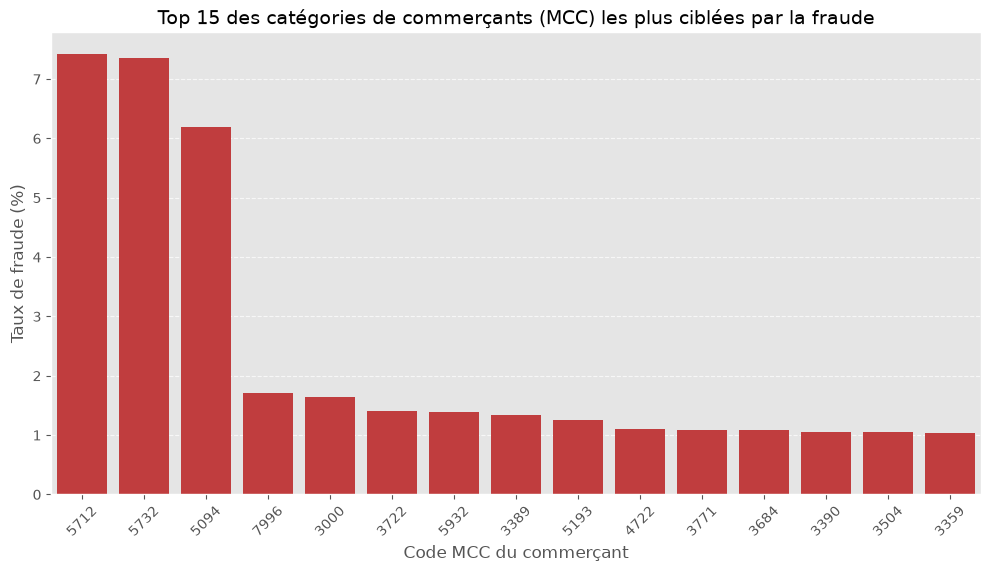

In [31]:
mcc_stats = df.groupby('MCC').agg(Total_Transactions=('Is_Fraud_Bin', 'count'),Fraud_Rate=('Is_Fraud_Bin', 'mean'))
mcc_stats['Fraud_Rate'] = mcc_stats['Fraud_Rate'] * 100

mcc_robust = mcc_stats[mcc_stats['Total_Transactions'] >= 1000]

top_15_risky_mcc = mcc_robust.sort_values(by='Fraud_Rate', ascending=False).head(15)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_15_risky_mcc.index, y=top_15_risky_mcc['Fraud_Rate'], order=top_15_risky_mcc.index,color='#d62728')

plt.title("Top 15 des catégories de commerçants (MCC) les plus ciblées par la fraude", fontsize=14)
plt.xlabel("Code MCC du commerçant", fontsize=12)
plt.ylabel("Taux de fraude (%)", fontsize=12)

plt.xticks(range(len(top_15_risky_mcc)), top_15_risky_mcc.index.astype(str), rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

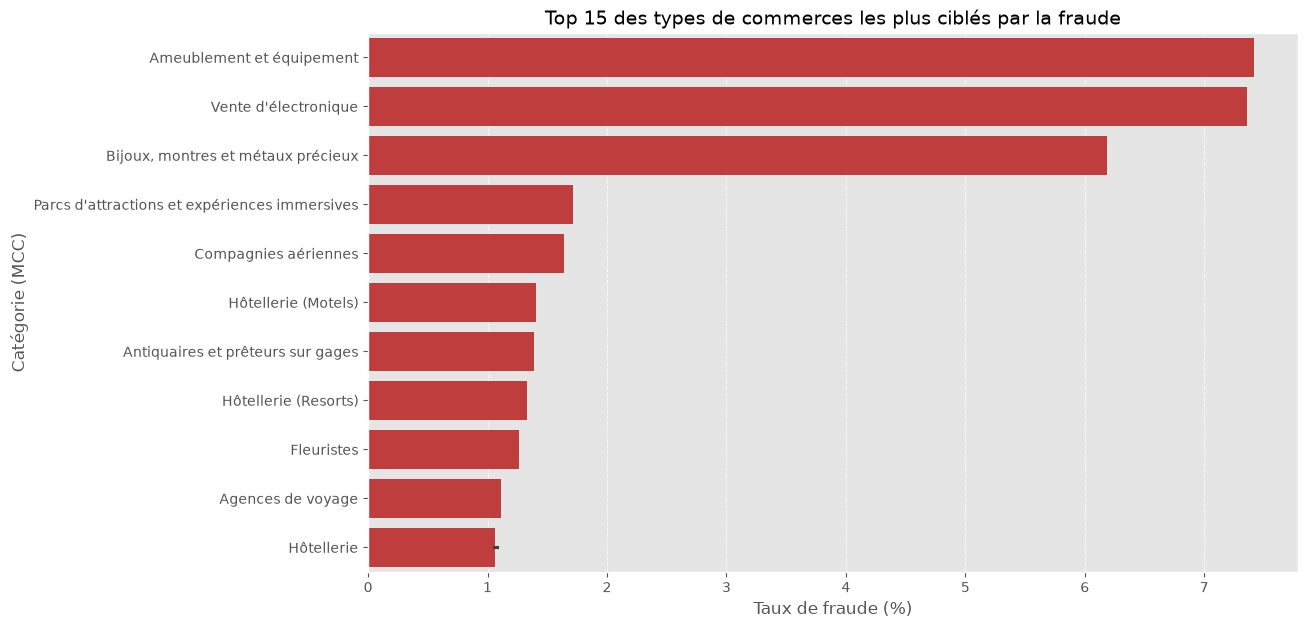

In [32]:
mcc_dict = {
    5712: "Ameublement et équipement",
    5732: "Vente d'électronique",
    5094: "Bijoux, montres et métaux précieux",
    7996: "Parcs d'attractions et expériences immersives",
    3000: "Compagnies aériennes",
    3722: "Hôtellerie (Motels)",
    5932: "Antiquaires et prêteurs sur gages",
    3389: "Hôtellerie (Resorts)",
    5193: "Fleuristes",
    4722: "Agences de voyage",
    3771: "Hôtellerie",
    3684: "Hôtellerie",
    3390: "Hôtellerie",
    3504: "Hôtellerie",
    3359: "Hôtellerie"
}
top_15_risky_mcc['Description'] = top_15_risky_mcc.index.map(mcc_dict).fillna('Autre commerce')

plt.figure(figsize=(12, 7))

sns.barplot(x='Fraud_Rate', y='Description', data=top_15_risky_mcc,color='#d62728')

plt.title("Top 15 des types de commerces les plus ciblés par la fraude", fontsize=14)
plt.xlabel("Taux de fraude (%)", fontsize=12)
plt.ylabel("Catégorie (MCC)", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()

L'analyse des taux de fraude par catégorie de commerçants révèle un ciblage de la part des fraudeurs. Les trois secteurs les plus touchés sont l'ameublement, l'électronique et la bijouterie, avec des taux avoisinant les 6 % à 7 %. Cette tendance s'explique logiquement par la nature de ces biens : ils sont de forte valeur et très faciles à écouler.Il est également intéressant d'observer la présence des parcs d'attractions et des expériences immersives au pied du podium. Les billets pour ces types de loisirs, s'achètent de manière instantanée et se revendent très facilement sans vérification d'identité à l'entrée, constituant une cible numérique. Enfin, on constate une grande représentation du secteur du voyage (compagnies aériennes, agences de voyage et diverses catégories d'hôtellerie).